# 4.1.4-RT bulk-derived signatures

**Inés Sentís**

Rhabdoid Tumor signature from external bulk RNA-seq cohort

Date of execution

In [1]:
Sys.Date()

[1] "2026-03-25"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Seurat)
library(Signac)
library(tidyverse)
library(edgeR)
library(ComplexHeatmap)
library(here)
library(glue)
}))

## Parameters

In [3]:
#here::dr_here(show_reason = TRUE)
source(here("utils/bin.R"))
source(here("utils/paths.R"))
source(here("AVGUSTINOVA_02_to_30/utils/style.R"))

set.seed(0)

## Load Data

In [4]:
combined_obj <- readRDS(here(glue("{int}/{robj_dir}/4.0.5-integrated_filt.rds")))
DefaultAssay(combined_obj) <- "RNA"

In [5]:
combined_obj@meta.data$clusters_donor <- paste(combined_obj@meta.data$patient, combined_obj@meta.data$clusters, sep=":")
combined_obj <- SetIdent(combined_obj, value=combined_obj@meta.data$clusters_donor)
list_objects <- SplitObject(combined_obj, split.by = "ident")
list_objects <- list_objects[match(levels(combined_obj), names(list_objects))]
col_names <-  names(list_objects)

In [6]:
df_sign <- read_csv(here(glue("external_data/bulk_rhab_signatures/rt_general.csv")),show_col_types = FALSE)
df_sign$source <- "RT SIG"
df_sign$target <- df_sign$gene
df_sign$mor <- df_sign$meanlog2fc

## Compute Multivariate Linear Model (MLM) 

In [7]:
list_res <- list()

for (c in col_names) {
    res <- decoupleR::run_mlm(list_objects[[c]]@assays$RNA@data, df_sign)
    res$cluster <- c
    list_res[[c]] <- res
}

In [8]:
df_res <- do.call(rbind, list_res)

In [9]:
write_csv(df_res, here(glue("{int}/{robj_dir}/4.1.4-Signature_RT_general.csv")))

In [10]:
head(df_res)

statistic,source,condition,score,p_value,cluster
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
mlm,RT SIG,p10_AAACAGCCAGACAAAC-1,1.1683569,0.2426711,p10:Tumor ANXA2
mlm,RT SIG,p10_AAACCGAAGGCAGGTG-1,1.0898130,0.2758034,p10:Tumor ANXA2
mlm,RT SIG,p10_AAACGTACAGAGGGAG-1,0.8826528,0.3774302,p10:Tumor ANXA2
mlm,RT SIG,p10_AAATCCGGTCTCAGCC-1,0.5786377,0.5628376,p10:Tumor ANXA2
mlm,RT SIG,p10_AACAAGCCAGCCAGAA-1,0.6830930,0.4945528,p10:Tumor ANXA2
mlm,RT SIG,p10_AACGCCCAGCTGGCTA-1,1.3537149,0.1758365,p10:Tumor ANXA2


In [11]:
# Assign colors based on patient ID prefix
assign_colors <- function(data_list, color_list) {
  names(data_list) <- sapply(data_list, function(x) {
    # Extract patient ID using regex
    patient_id <- sub("^(p[0-9]+).*", "\\1", x)
    return(patient_id)
  })
  
  # Generate color list by mapping each element to its patient color
  color_assignment <- lapply(names(data_list), function(id) color_list[[id]])
  names(color_assignment) <- data_list
  
  return(color_assignment)
}

# Run function
colored_list <- assign_colors(col_names, colors_patients)

In [12]:
custom_order <- c('p2','p8','p14','p17','p13','p9','p7','p6','p15','p10','p16','p3','p5','p1','p4','p19')
df_res <- df_res %>%
  mutate(patient = str_trim(str_extract(cluster, "^[^:]+"))) %>%
  mutate(patient = factor(patient, levels = custom_order))
df_res <- df_res %>% 
  arrange(patient, cluster)
df_res$cluster <- factor(df_res$cluster, levels = unique(df_res$cluster))

In [13]:
cutoff <- quantile(df_res$score, 0.10, na.rm = TRUE)

vlp <- ggplot(df_res, aes(x = cluster, y = score, color = cluster, fill = cluster)) + 
    geom_violin(color = "black", alpha = 0.7) +
    ggrastr::geom_jitter_rast(width = 0.15, size = 0.8, alpha = 0.3) +
    stat_summary(fun = median, geom = "point", size = 2, color = "black", fill = "black") +
    theme_classic() + 
    geom_hline(yintercept = cutoff, linetype = "dashed", color = "darkgray", size = 0.8) +
    annotate("text", x = -0.5, y = cutoff, label = "Q10", 
             color = "darkgray", fontface = "italic",
             vjust = -0.5, hjust = 0, size = 3.5) +
    ggtitle("RT signature") +
    theme(
        plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
        axis.text.x = element_text(hjust = 1, color = "black"),
        axis.text.y = element_text(color = "black"),
        plot.margin = margin(t = 10, r = 20, b = 20, l = 10)
    ) +
    scale_fill_manual(breaks = names(colored_list), values = unlist(colored_list, use.name = FALSE)) +
    scale_color_manual(breaks = names(colored_list), values = unlist(colored_list, use.name = FALSE))

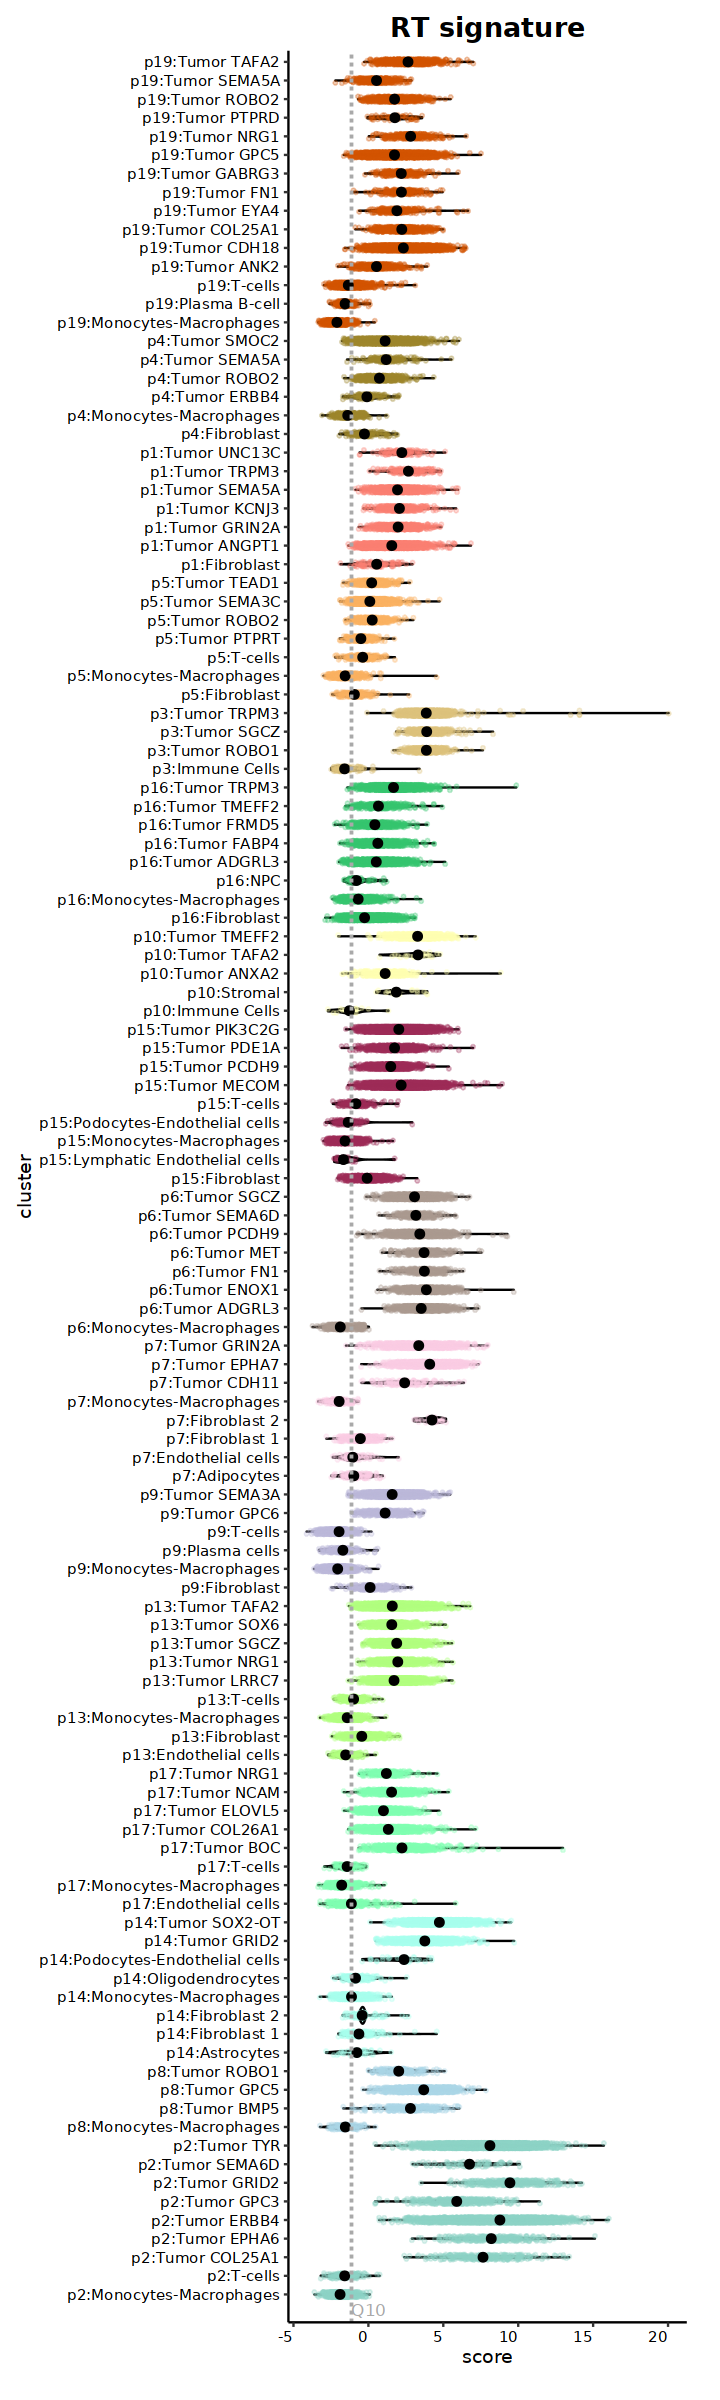

In [14]:
options(repr.plot.width = 6, repr.plot.height = 20)
vlp <- vlp + NoLegend() + coord_flip()
vlp

In [15]:
ggsave(plot = vlp, width = 6, height = 20, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.1.4-Violin_RT_general_l2.svg")))

In [16]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] glue_1.6.2            here_1.0.1            ComplexHeatmap_2.10.0
 [4] edgeR_3.36.0          limma_3.50.3          lubridate_1.9.3      
 [7] forcats_1.0.0         stringr_1.5.0         dplyr_1.1.3          
[10] purrr_1.0.2           readr_2.1.4           tidyr